# BÀI TẬP NHÓM LAB02: QUI TRÌNH MÁY HỌC CHO DỰ ĐOÁN GIÁ NHÀ
**Học phần**: Học sâu (Deep Learning) - **Mã HP**: 858048  
**Lớp**: DDU1231 - **Nhóm lớp**: 01  
**Giảng viên hướng dẫn**: TS. Đỗ Như Tài  

### Thành viên nhóm thực hiện:
1. **Phan Đồng Minh Quân** - MSSV: **3123580038** (Nhóm trưởng)
2. **Võ Minh Tiến** - MSSV: **3123580053**

---
## GIAI ĐOẠN 1: BUSINESS UNDERSTANDING (HIỂU BÀI TOÁN)
* **Bối cảnh kinh doanh**: Thị trường bất động sản tại Ames, Iowa sở hữu tính đa dạng cao với 79 biến giải thích mô tả chi tiết từ diện tích, kết cấu móng, năm xây dựng, vật liệu ngoại thất đến khu vực lân cận.
* **Mục tiêu kỹ thuật**: Dự đoán giá bán căn nhà (`SalePrice`) với độ chính xác cao nhất thông qua mô hình học sâu **Multi-Layer Perceptron (MLP)** xây dựng bằng **PyTorch**, đồng thời mở rộng so sánh và kết hợp (Ensemble) với các mô hình Gradient Boosting (XGBoost, CatBoost) và Linear Regression (Lasso, Ridge).
* **Độ đo đánh giá**: Root Mean Squared Error trên logarit biến mục tiêu:
$$\text{RMSE}_{\log} = \sqrt{\frac{1}{N} \sum_{i=1}^N \left( \log(1 + y_i) - \log(1 + \hat{y}_i) \right)^2 }$$
* **Quy trình chuẩn**: Toàn bộ dự án được triển khai theo quy trình 6 bước **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*).


In [1]:
import os, sys, glob, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
import xgboost as xgb
import catboost as cb

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
print("Đã tải đầy đủ các thư viện cần thiết!")


PyTorch Version: 2.14.0+cpu
CUDA Available:  False
Đã tải đầy đủ các thư viện cần thiết!


---
## GIAI ĐOẠN 2: DATA UNDERSTANDING (KHÁM PHÁ DỮ LIỆU)
### 2.1. Cấu hình kịch bản thí nghiệm (Experiment Configuration)
Quản lý toàn bộ thông số, đường dẫn lưu trữ mô hình và kết quả thông qua cấu trúc từ điển `params` tập trung.


In [2]:
params = {
    "data": {
        "train_file": "train.csv",
        "test_file": "test.csv",
        "validation_size": 0.25,
        "random_state": 42
    },
    "experiment": {
        "expr_dir": "./experiments",
        "expr_name": "house_mlp_v1",
        "best_model_file": "./experiments/house_mlp_v1/best_model.pt",
        "best_tuned_model_file": "./experiments/house_mlp_v1/best_tuned_model.pt",
        "params_file": "./experiments/house_mlp_v1/params.json",
        "tuning_results_file": "./experiments/house_mlp_v1/tuning_results.csv",
        "evaluation_metrics_file": "./experiments/house_mlp_v1/evaluation_metrics.csv",
        "images_dir": "./experiments/house_mlp_v1/images",
        "submission_file": "submission.csv"
    },
    "train": {
        "hidden1": 48,
        "hidden2": 24,
        "dropout": 0.20,
        "learning_rate": 0.003,
        "weight_decay": 0.003,
        "batch_size": 32,
        "epochs": 120
    }
}

os.makedirs(params["experiment"]["images_dir"], exist_ok=True)
with open(params["experiment"]["params_file"], "w", encoding="utf-8") as f:
    json.dump(params, f, indent=4, ensure_ascii=False)

print("Cấu hình thí nghiệm đã được khởi tạo và lưu trữ thành công!")


Cấu hình thí nghiệm đã được khởi tạo và lưu trữ thành công!


### 2.2. Tải tập dữ liệu Ames Housing


In [3]:
train_raw = pd.read_csv(params["data"]["train_file"])
test_raw = pd.read_csv(params["data"]["test_file"])

print(f"Kích thước tập huấn luyện gốc (Train Raw): {train_raw.shape}")
print(f"Kích thước tập kiểm tra gốc (Test Raw):     {test_raw.shape}")
print("\nTổng quan 5 dòng đầu tiên:")
display(train_raw[["Id", "MSSubClass", "Neighborhood", "OverallQual", "GrLivArea", "TotalBsmtSF", "SalePrice"]].head())


Kích thước tập huấn luyện gốc (Train Raw): (1460, 81)
Kích thước tập kiểm tra gốc (Test Raw):     (1459, 80)

Tổng quan 5 dòng đầu tiên:
   Id  MSSubClass Neighborhood  OverallQual  GrLivArea  TotalBsmtSF  SalePrice
0   1          60      CollgCr            7       1710          856     208500
1   2          20      Veenker            6       1262         1262     181500
2   3          60      CollgCr            7       1786          920     223500
3   4          70      Crawfor            7       1717          756     140000
4   5          60      NoRidge            8       2198         1145     250000


### 2.3. Khảo sát giá trị khuyết (Missing Values)


Số lượng thuộc tính bị khuyết dữ liệu: 19 thuộc tính
              Số lượng thiếu  Tỷ lệ (%)
PoolQC                  1453      99.52
MiscFeature             1406      96.30
Alley                   1369      93.77
Fence                   1179      80.75
MasVnrType               872      59.73
FireplaceQu              690      47.26
LotFrontage              259      17.74
GarageType                81       5.55
GarageYrBlt               81       5.55
GarageFinish              81       5.55


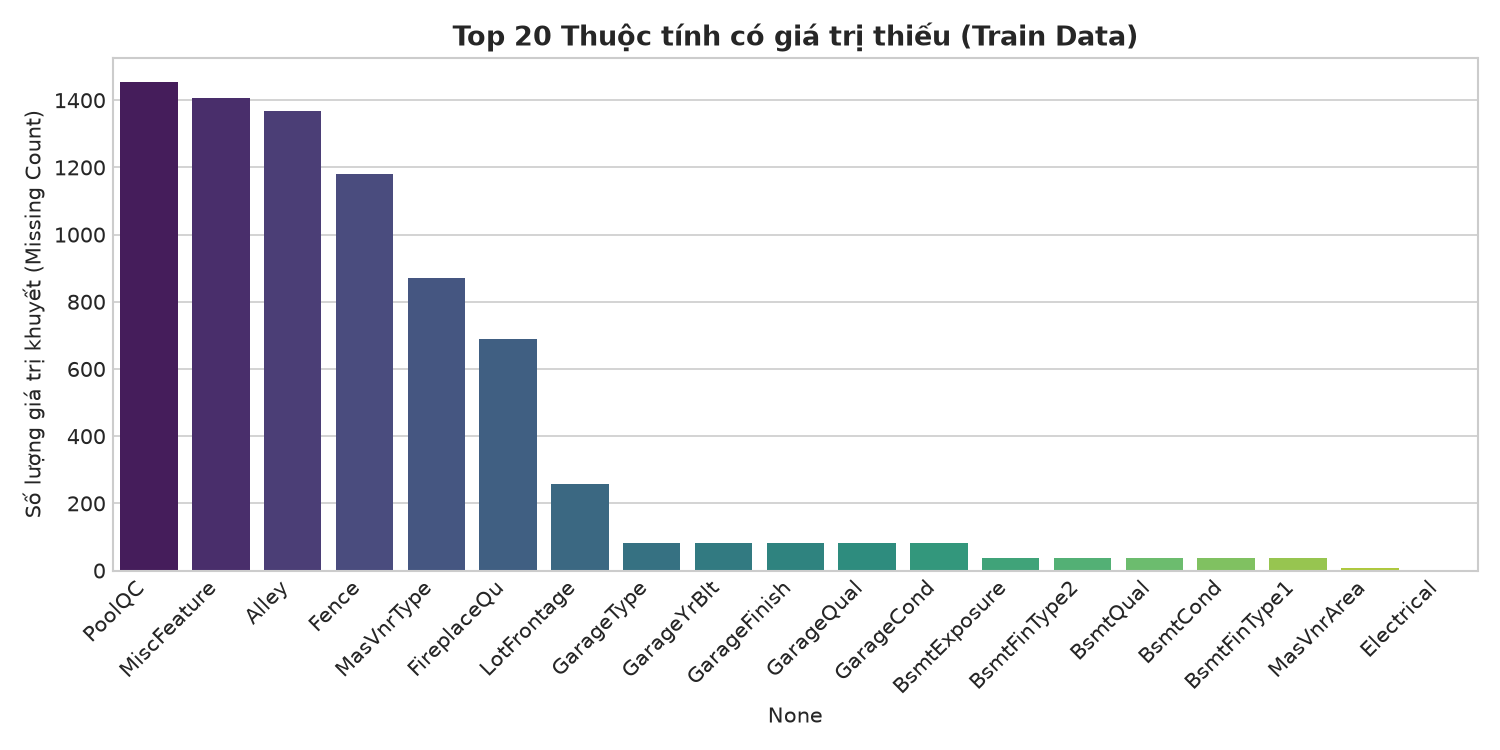

In [4]:
missing = train_raw.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_ratio = (missing / len(train_raw)) * 100

print(f"Số lượng thuộc tính bị khuyết dữ liệu: {len(missing)} thuộc tính")
print(pd.DataFrame({"Số lượng thiếu": missing, "Tỷ lệ (%)": missing_ratio.round(2)}).head(10))

plt.figure(figsize=(10, 4.5))
sns.barplot(x=missing.index[:20], y=missing.values[:20], palette="viridis")
plt.xticks(rotation=45, ha='right')
plt.title("Top 20 Thuộc tính có giá trị thiếu (Train Data)", fontsize=13, fontweight='bold')
plt.ylabel("Số lượng giá trị khuyết (Count)")
plt.tight_layout()
plt.show()


### 2.4. Phân phối biến mục tiêu `SalePrice` và phép biến đổi Logarit
`SalePrice` có độ lệch phải (Positive Skewness) rõ rệt. Phép biến đổi $y = \log(1 + \text{SalePrice})$ giúp đưa phân phối về dạng gần chuẩn Gauss, giảm thiểu ảnh hưởng của ngoại lệ giá cao và ổn định phương sai cho mạng nơ-ron.


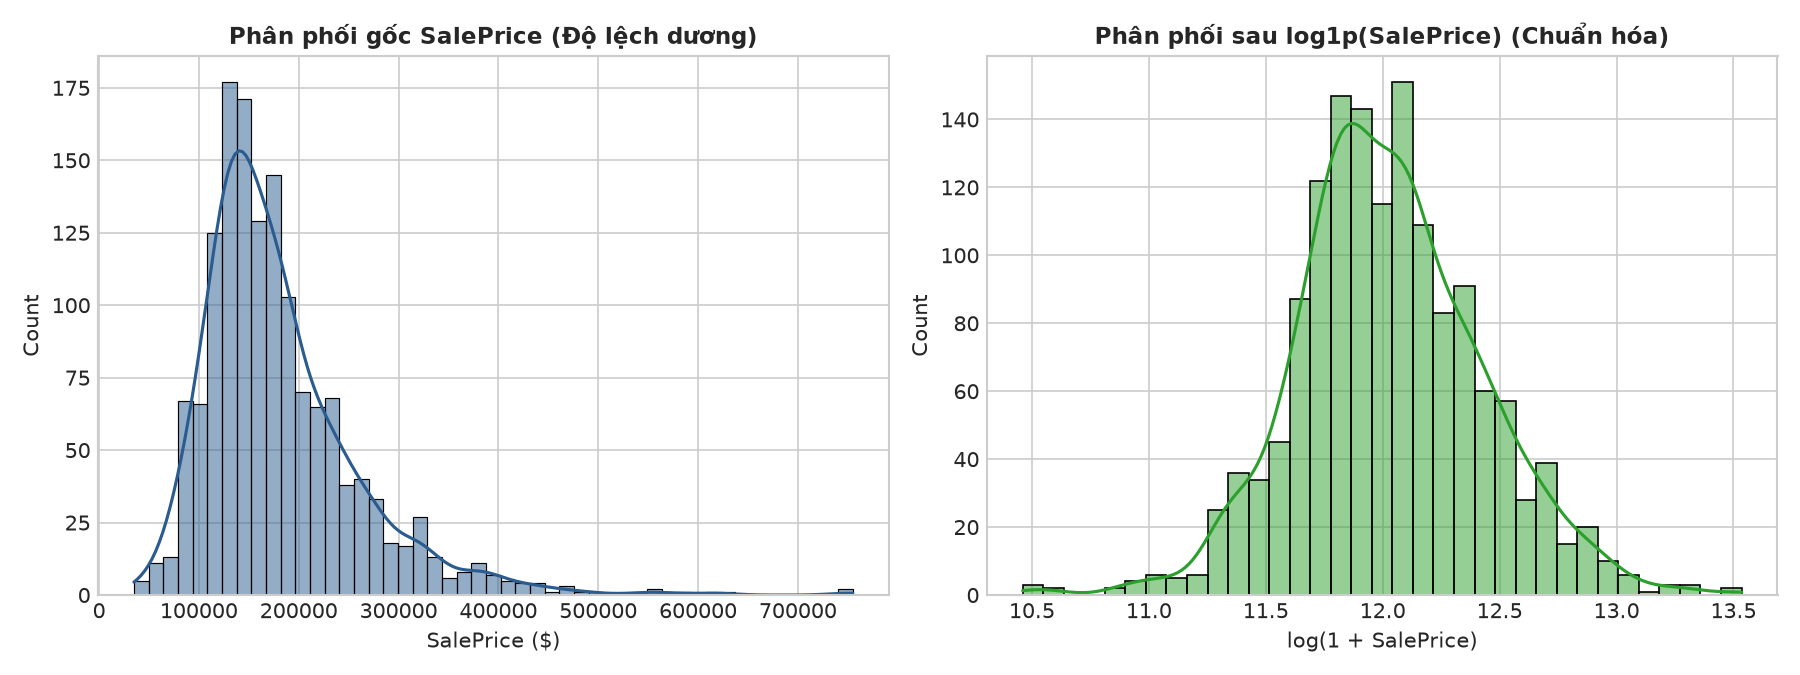

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(train_raw["SalePrice"], kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title(f"Phân phối gốc SalePrice (Skewness: {train_raw['SalePrice'].skew():.2f})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("SalePrice ($)")

log_price = np.log1p(train_raw["SalePrice"])
sns.histplot(log_price, kde=True, ax=axes[1], color="#2ca02c")
axes[1].set_title(f"Phân phối sau log1p (Skewness: {log_price.skew():.2f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()


### 2.5. Phát hiện điểm ngoại lệ (Outliers) theo khuyến nghị Dean De Cock (2011)
Trong bài báo khoa học *"Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project"* (Journal of Statistics Education, 2011), tác giả Dean De Cock chỉ rõ:
> *"I would recommend removing any houses with more than 4000 square feet from the data set (which eliminates these five unusual observations) or simply removing the two abnormal sales with GrLivArea > 4000 and SalePrice < 300000."*

Ta quan sát thấy 2 căn nhà có diện tích sinh hoạt cực lớn (`GrLivArea > 4000 sqft`) nhưng giá bán lại thấp bất thường dưới $300,000 (cụ thể là Id 524 và Id 1299). Đây là những giao dịch đất đai/nông nghiệp đặc biệt không phản ánh đúng thị trường nhà ở dân cư bình thường.


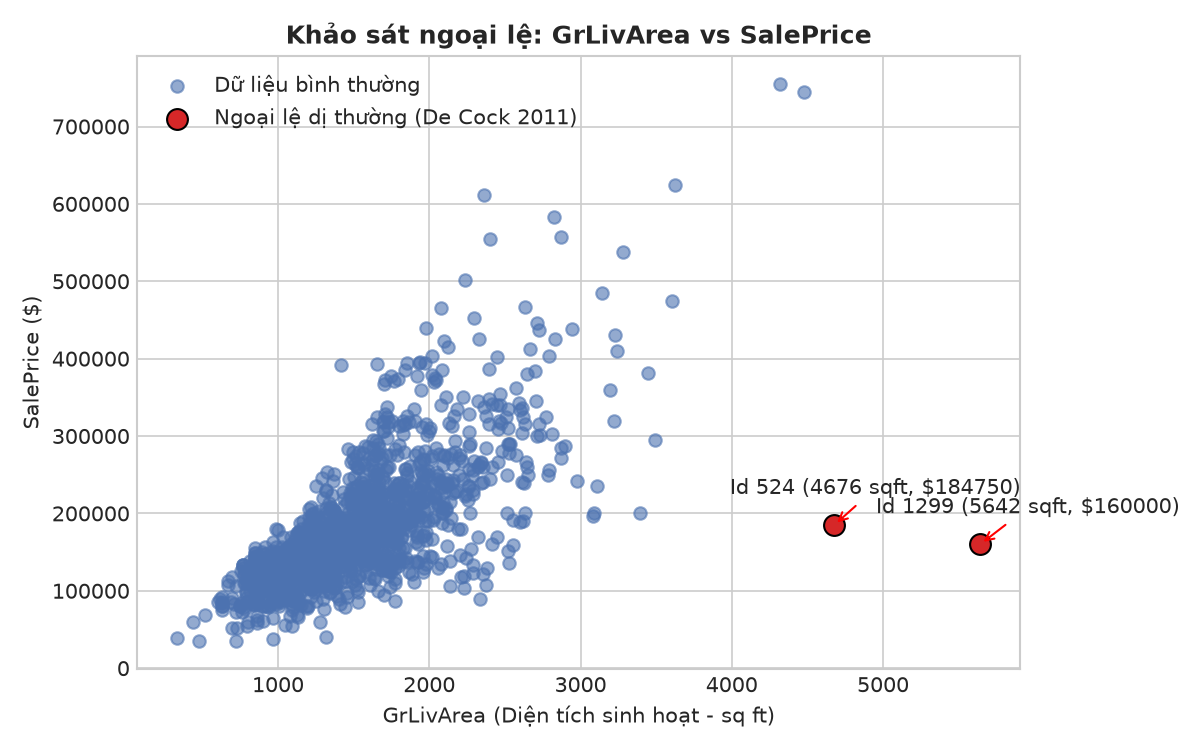

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(train_raw["GrLivArea"], train_raw["SalePrice"], alpha=0.6, color="#4c72b0", label="Dữ liệu bình thường")

outliers = train_raw[(train_raw["GrLivArea"] > 4000) & (train_raw["SalePrice"] < 300000)]
plt.scatter(outliers["GrLivArea"], outliers["SalePrice"], color="#d62728", s=120, edgecolors='black', label="Ngoại lệ dị thường (De Cock 2011)")

for _, row in outliers.iterrows():
    plt.annotate(f"Id {int(row['Id'])} ({int(row['GrLivArea'])} sqft, ${int(row['SalePrice'])})",
                 (row["GrLivArea"], row["SalePrice"]),
                 textcoords="offset points", xytext=(-50, 15),
                 arrowprops=dict(arrowstyle="->", color="red"))

plt.title("Khảo sát ngoại lệ: GrLivArea vs SalePrice", fontsize=12, fontweight='bold')
plt.xlabel("GrLivArea (Diện tích sinh hoạt - sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()


Loại bỏ chính xác 2 điểm ngoại lệ dị thường theo Dean De Cock (2011):


Số lượng mẫu ban đầu:            1460
Số lượng mẫu sau khi lọc ngoại lệ: 1458 (đã loại đúng 2 ngoại lệ dị thường)


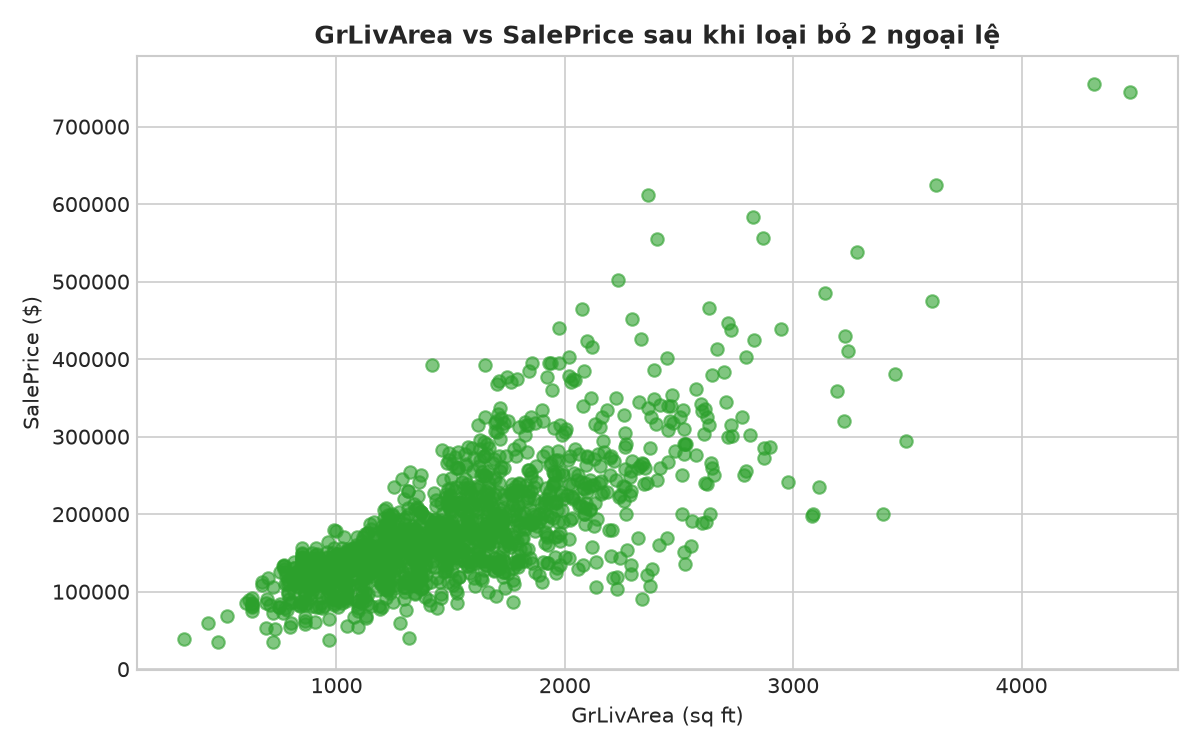

In [7]:
train_cleaned = train_raw[~((train_raw["GrLivArea"] > 4000) & (train_raw["SalePrice"] < 300000))].copy().reset_index(drop=True)
print(f"Số lượng mẫu ban đầu:            {len(train_raw)}")
print(f"Số lượng mẫu sau khi lọc ngoại lệ: {len(train_cleaned)} (đã loại đúng 2 ngoại lệ dị thường)")

plt.figure(figsize=(8, 4.5))
plt.scatter(train_cleaned["GrLivArea"], train_cleaned["SalePrice"], alpha=0.6, color="#2ca02c")
plt.title("GrLivArea vs SalePrice sau khi loại bỏ 2 ngoại lệ dị thường", fontsize=12, fontweight='bold')
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()


---
## GIAI ĐOẠN 3: DATA PREPARATION (TIỀN XỬ LÝ & KỸ NGHỆ ĐẶC TRƯNG)
### 3.1. Chiến lược xử lý giá trị khuyết chuyên biệt (Domain-Specific Imputation)
1. **Thuộc tính phân loại mà `NA` mang nghĩa "Không có" (None)**:
   * Theo tài liệu `data_description.txt`, các thuộc tính như `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`, `BsmtQual`, `BsmtCond`, `BsmtExposure`, `BsmtFinType1`, `BsmtFinType2`, `FireplaceQu`, `Fence`, `Alley`, `MiscFeature`, `PoolQC`, `MasVnrType` nếu mang giá trị `NA` thì thực chất là căn nhà **không có** nhà để xe, không có hầm, không có lò sưởi hay hồ bơi. Do đó ta gán giá trị mang ý nghĩa thực tế là `'None'`.
2. **Thuộc tính số mà `NA` nghĩa là số lượng bằng 0**:
   * Các cột diện tích hoặc số lượng hầm, garage tương ứng (`GarageCars`, `GarageArea`, `TotalBsmtSF`, `BsmtFullBath`,...) được điền bằng `0`.
3. **Thuộc tính chiều rộng mặt tiền `LotFrontage`**:
   * Chiều rộng mặt tiền phụ thuộc chặt chẽ vào quy hoạch từng khu phố. Nhóm sử dụng giá trị trung vị (`median`) của từng khu vực `Neighborhood` tương ứng để điền khuyết.

### 3.2. Kỹ nghệ đặc trưng mới (Domain Feature Engineering)
Dựa trên kiến thức thẩm định bất động sản thực tế, nhóm xây dựng các đặc trưng tổng hợp:
* **`TotalSF`**: Tổng diện tích xây dựng có mái che $= \text{TotalBsmtSF} + \text{1stFlrSF} + \text{2ndFlrSF}$.
* **`TotalBath`**: Tổng số phòng tắm $= \text{FullBath} + 0.5 \times \text{HalfBath} + \text{BsmtFullBath} + 0.5 \times \text{BsmtHalfBath}$.
* **`HouseAge`**: Tuổi của ngôi nhà tại thời điểm bán $= \text{YrSold} - \text{YearBuilt}$.
* **`RemodAge`**: Số năm kể từ lần cải tạo cuối cùng $= \text{YrSold} - \text{YearRemodAdd}$.
* **`IsRemodeled`**: Căn nhà đã từng được sửa chữa, nâng cấp chưa $= 1$ nếu $\text{YearRemodAdd} \neq \text{YearBuilt}$, ngược lại $= 0$.
* **`TotalPorchSF`**: Tổng diện tích hiên $= \text{WoodDeckSF} + \text{OpenPorchSF} + \text{EnclosedPorch} + \text{3SsnPorch} + \text{ScreenPorch}$.


In [8]:
def preprocess_housing(train_df, test_df):
    y = np.log1p(train_df["SalePrice"].values)
    
    train_feat = train_df.drop(columns=["Id", "SalePrice"])
    test_feat = test_df.drop(columns=["Id"])
    
    combined = pd.concat([train_feat, test_feat], axis=0).reset_index(drop=True)
    
    # 1. Điền 'None' cho các biến phân loại
    none_cols = [
        "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
        "GarageType", "GarageFinish", "GarageQual", "GarageCond",
        "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
        "MasVnrType"
    ]
    for c in none_cols:
        combined[c] = combined[c].fillna("None")
        
    # 2. Điền 0 cho các biến số hầm và garage
    zero_cols = [
        "GarageYrBlt", "GarageCars", "GarageArea",
        "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
        "BsmtFullBath", "BsmtHalfBath", "MasVnrArea"
    ]
    for c in zero_cols:
        combined[c] = combined[c].fillna(0)
        
    # 3. Điền LotFrontage theo median của Neighborhood
    combined["LotFrontage"] = combined.groupby("Neighborhood")["LotFrontage"].transform(lambda x: x.fillna(x.median()))
    combined["LotFrontage"] = combined["LotFrontage"].fillna(combined["LotFrontage"].median())
    
    # 4. Điền mode cho các biến chuỗi còn lại
    cat_cols = combined.select_dtypes(include=["object", "string"]).columns
    for c in cat_cols:
        combined[c] = combined[c].fillna(combined[c].mode()[0])
        
    # 5. Điền median cho các biến số còn lại
    num_cols = combined.select_dtypes(include=[np.number]).columns
    for c in num_cols:
        combined[c] = combined[c].fillna(combined[c].median())
        
    # 6. Feature Engineering
    combined["TotalSF"] = combined["TotalBsmtSF"] + combined["1stFlrSF"] + combined["2ndFlrSF"]
    combined["TotalBath"] = combined["FullBath"] + 0.5 * combined["HalfBath"] + combined["BsmtFullBath"] + 0.5 * combined["BsmtHalfBath"]
    combined["HouseAge"] = combined["YrSold"] - combined["YearBuilt"]
    combined["RemodAge"] = combined["YrSold"] - combined["YearRemodAdd"]
    combined["IsRemodeled"] = (combined["YearRemodAdd"] != combined["YearBuilt"]).astype(int)
    combined["TotalPorchSF"] = combined["WoodDeckSF"] + combined["OpenPorchSF"] + combined["EnclosedPorch"] + combined["3SsnPorch"] + combined["ScreenPorch"]
    combined["HasGarage"] = (combined["GarageArea"] > 0).astype(int)
    combined["HasBsmt"] = (combined["TotalBsmtSF"] > 0).astype(int)
    combined["HasFireplace"] = (combined["Fireplaces"] > 0).astype(int)
    
    # 7. One-hot encoding
    encoded_df = pd.get_dummies(combined, drop_first=True)
    
    n_train = len(train_df)
    X_train_df = encoded_df.iloc[:n_train].copy()
    X_test_df = encoded_df.iloc[n_train:].copy()
    
    return X_train_df, y, X_test_df

X_train_df, y_all, X_test_df = preprocess_housing(train_cleaned, test_raw)
print(f"Số lượng chiều đặc trưng sau mã hóa One-Hot: {X_train_df.shape[1]}")
print(f"Kích thước X_train: {X_train_df.shape}")
print(f"Kích thước X_test:  {X_test_df.shape}")


Số lượng chiều đặc trưng sau mã hóa One-Hot: 267
Kích thước X_train: (1458, 267)
Kích thước X_test:  (1459, 267)


Khảo sát hệ số tương quan của đặc trưng mới sinh `TotalSF` đối với giá nhà:


Hệ số tương quan Pearson giữa TotalSF và SalePrice: r = 0.8329


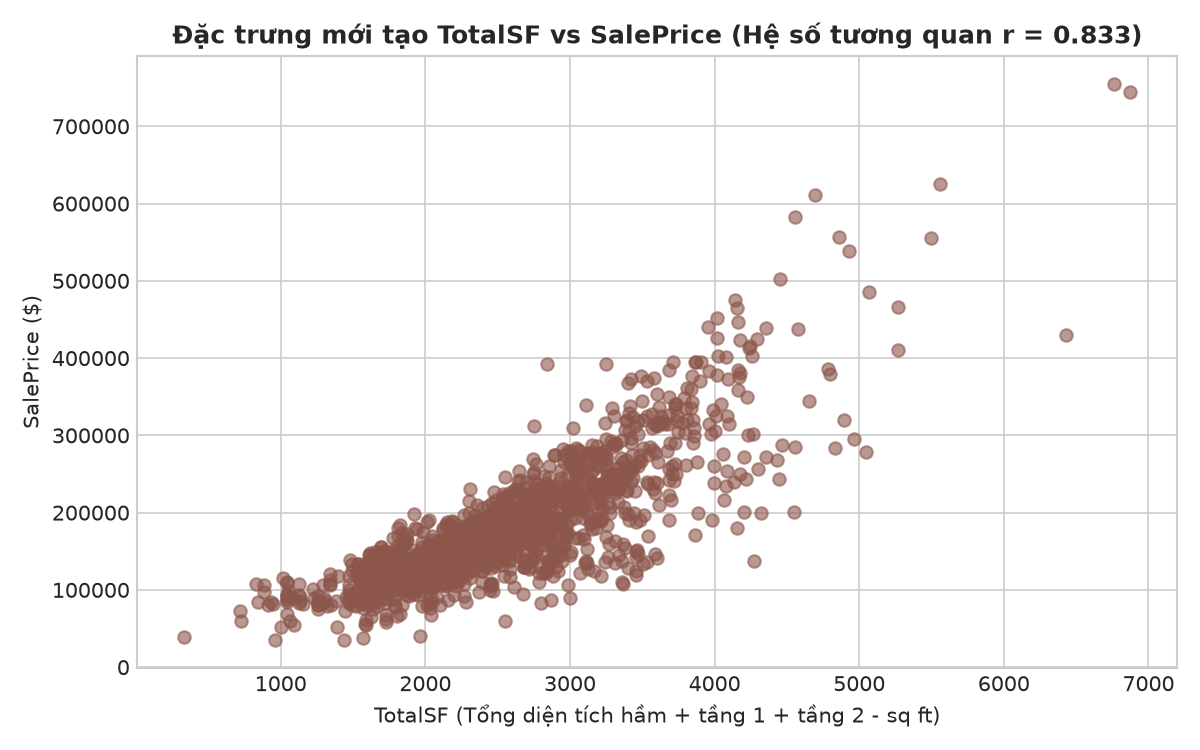

In [9]:
corr_val = pd.Series(X_train_df['TotalSF']).corr(pd.Series(np.expm1(y_all)))
print(f"Hệ số tương quan Pearson giữa TotalSF và SalePrice: r = {corr_val:.4f}")

plt.figure(figsize=(8, 4.5))
plt.scatter(X_train_df["TotalSF"], np.expm1(y_all), alpha=0.6, color="#8c564b")
plt.title(f"Đặc trưng mới tạo TotalSF vs SalePrice (Hệ số tương quan r = {corr_val:.3f})", fontsize=12, fontweight='bold')
plt.xlabel("TotalSF (Tổng diện tích hầm + tầng 1 + tầng 2 - sq ft)")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()


### 3.3. Phân chia tập dữ liệu, Chuẩn hóa đặc trưng & Chuyển đổi PyTorch Tensors
* **Tỷ lệ phân chia**: 75% Huấn luyện (Train) và 25% Đánh giá (Validation) với `random_state=42`.
* **Chuẩn hóa StandardScaler**: Fit trên tập huấn luyện $X_{\text{train}}$, sau đó transform cho $X_{\text{val}}$ và $X_{\text{test}}$ để tránh data leakage.
* **Chuyển đổi Tensor**: Chuyển ma trận số thực sang kiểu `torch.float32` sẵn sàng nạp vào DataLoader của PyTorch.


X_train tensor: torch.Size([1093, 267]), y_train tensor: torch.Size([1093, 1])
X_val tensor:   torch.Size([365, 267]), y_val tensor:   torch.Size([365, 1])
X_test tensor:  torch.Size([1459, 267])


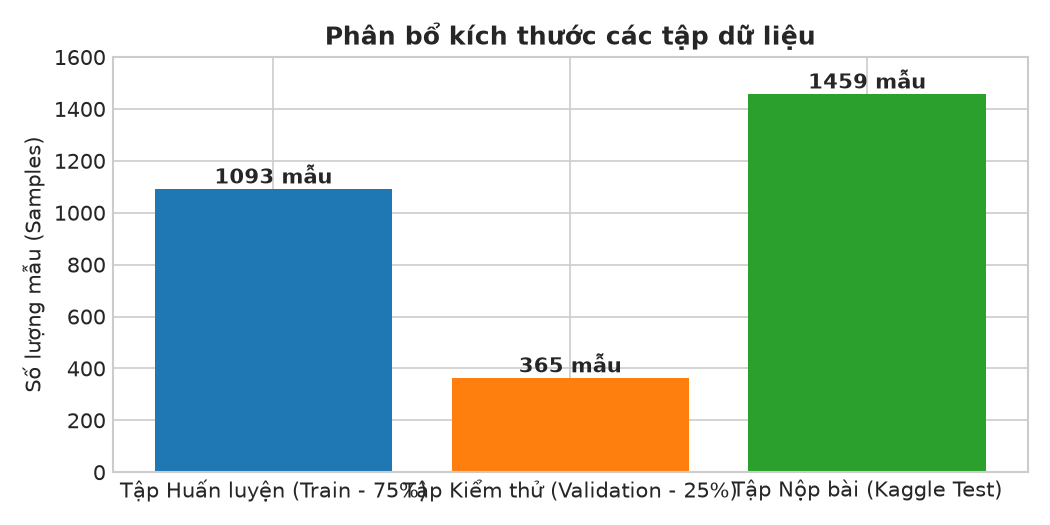

In [10]:
X_tr_np, X_val_np, y_tr_np, y_val_np = train_test_split(
    X_train_df.values.astype(np.float32),
    y_all.astype(np.float32),
    test_size=params["data"]["validation_size"],
    random_state=params["data"]["random_state"]
)

scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr_np)
X_val_scaled = scaler.transform(X_val_np)
X_test_scaled = scaler.transform(X_test_df.values.astype(np.float32))

# Chuyển đổi sang PyTorch Tensors
X_tr_t = torch.tensor(X_tr_scaled, dtype=torch.float32)
y_tr_t = torch.tensor(y_tr_np, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val_np, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)

print(f"X_train tensor: {X_tr_t.shape}, y_train tensor: {y_tr_t.shape}")
print(f"X_val tensor:   {X_val_t.shape}, y_val tensor:   {y_val_t.shape}")
print(f"X_test tensor:  {X_test_t.shape}")

plt.figure(figsize=(7, 3.5))
bars = plt.bar(["Train (75%)", "Validation (25%)", "Kaggle Test"],
               [len(X_tr_np), len(X_val_np), len(X_test_df)], color=["#1f77b4", "#ff7f0e", "#2ca02c"])
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, f"{int(bar.get_height())} mẫu", ha='center', fontweight='bold')
plt.title("Phân bổ kích thước các tập dữ liệu", fontsize=12, fontweight='bold')
plt.ylabel("Số lượng mẫu (Samples)")
plt.ylim(0, 1600)
plt.tight_layout()
plt.show()


---
## GIAI ĐOẠN 4: MODELING (XÂY DỰNG & HUẤN LUYỆN MÔ HÌNH)
### 4.1. Thiết kế kiến trúc Mạng nơ-ron PyTorch MLP
Mạng Multi-Layer Perceptron (MLP) cho bài toán hồi quy giá nhà được xây dựng với các đặc điểm:
* Sử dụng hàm kích hoạt phi tuyến **`LeakyReLU(negative_slope=0.1)`** giúp ngăn chặn hiện tượng "Dying ReLU", đảm bảo gradient truyền đều qua mọi nơ-ron.
* Tích hợp kỹ thuật Regularization **`Dropout`** để ngăn chặn hiện tượng overfitting trên tập đặc trưng nhiều chiều.
* Sử dụng bộ tối ưu hóa **`Adam`** kết hợp tham số trừng phạt trọng số **`weight_decay`** (L2 Regularization).


In [11]:
class HousePriceMLP(nn.Module):
    def __init__(self, input_dim, hidden1=48, hidden2=24, dropout=0.20):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.LeakyReLU(0.1),
            nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2),
            nn.LeakyReLU(0.1),
            nn.Linear(hidden2, 1)
        )
    def forward(self, x):
        return self.net(x)

input_dim = X_tr_scaled.shape[1]
model_demo = HousePriceMLP(input_dim, hidden1=48, hidden2=24, dropout=0.20)
print("Cấu trúc mạng PyTorch MLP:")
print(model_demo)


Cấu trúc mạng PyTorch MLP:
HousePriceMLP(
  (net): Sequential(
    (0): Linear(in_features=267, out_features=48, bias=True)
    (1): LeakyReLU(negative_slope=0.1)
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=48, out_features=24, bias=True)
    (4): LeakyReLU(negative_slope=0.1)
    (5): Linear(in_features=24, out_features=1, bias=True)
  )
)


### 4.2. Huấn luyện mô hình MLP Baseline


MLP Baseline Validation RMSE: 0.15180 (Thời gian huấn luyện: 4.50s)


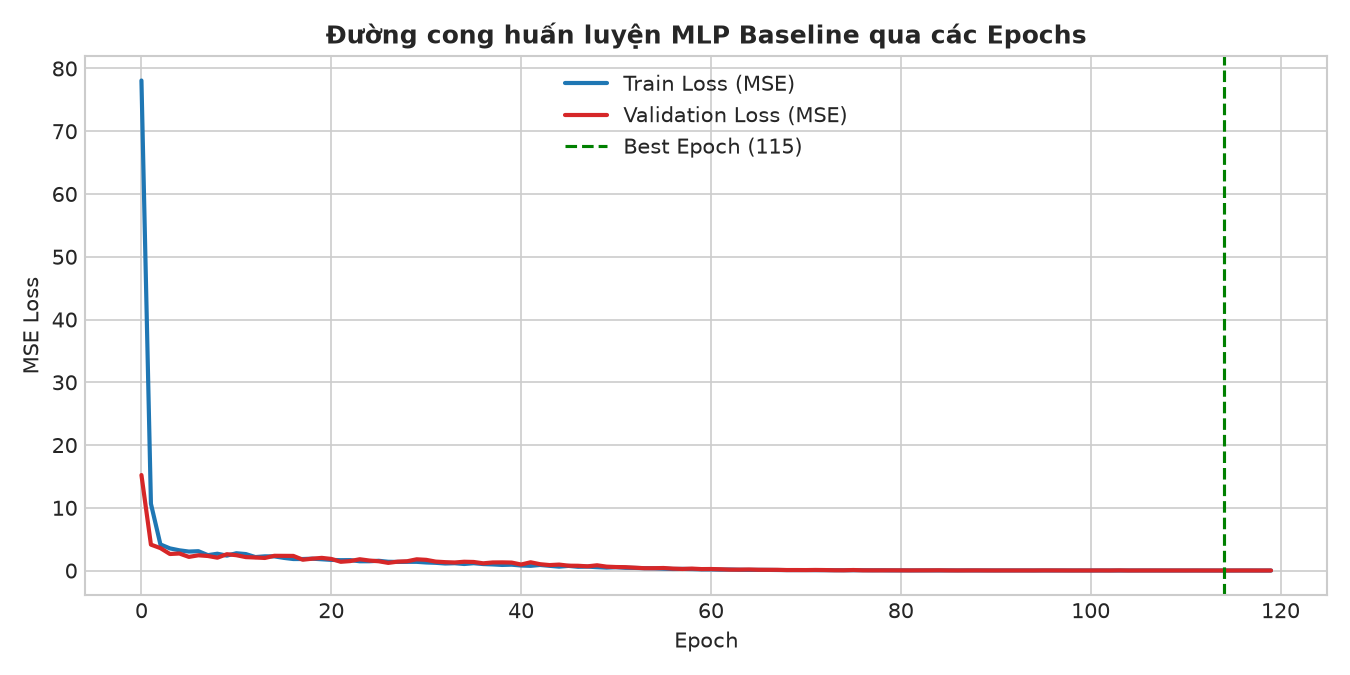

In [12]:
torch.manual_seed(42)
np.random.seed(42)

baseline_mlp = HousePriceMLP(input_dim, hidden1=48, hidden2=24, dropout=0.20)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(baseline_mlp.parameters(), lr=0.003, weight_decay=0.003)

train_loader = DataLoader(
    TensorDataset(X_tr_t, y_tr_t),
    batch_size=params["train"]["batch_size"],
    shuffle=True
)

epochs = 120
train_losses = []
val_losses = []
best_baseline_rmse = float("inf")
best_baseline_state = None

start_time = time.time()
for epoch in range(epochs):
    baseline_mlp.train()
    running_loss = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        preds = baseline_mlp(bx)
        loss = criterion(preds, by)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(bx)
    
    epoch_train_loss = running_loss / len(X_tr_t)
    train_losses.append(epoch_train_loss)
    
    baseline_mlp.eval()
    with torch.no_grad():
        v_preds = baseline_mlp(X_val_t)
        v_loss = criterion(v_preds, y_val_t).item()
        val_losses.append(v_loss)
        v_rmse = root_mean_squared_error(y_val_np, v_preds.squeeze().numpy())
        if v_rmse < best_baseline_rmse:
            best_baseline_rmse = v_rmse
            best_baseline_state = baseline_mlp.state_dict().copy()

mlp_baseline_time = time.time() - start_time
torch.save(best_baseline_state, params["experiment"]["best_model_file"])
baseline_mlp.load_state_dict(best_baseline_state)

baseline_mlp.eval()
with torch.no_grad():
    base_val_pred = baseline_mlp(X_val_t).squeeze().numpy()
baseline_val_rmse = root_mean_squared_error(y_val_np, base_val_pred)
print(f"MLP Baseline Validation RMSE: {baseline_val_rmse:.5f} (Thời gian huấn luyện: {mlp_baseline_time:.2f}s)")

plt.figure(figsize=(9, 4.5))
plt.plot(train_losses, label="Train Loss (MSE)", color="#1f77b4", linewidth=2)
plt.plot(val_losses, label="Validation Loss (MSE)", color="#d62728", linewidth=2)
plt.axvline(np.argmin(val_losses), color='green', linestyle='--', label=f"Best Epoch ({np.argmin(val_losses)+1})")
plt.title("Đường cong học tập MLP Baseline qua 120 Epochs", fontsize=12, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.tight_layout()
plt.show()


### 4.3. Tinh chỉnh siêu tham số (Hyperparameter Tuning) cho mạng MLP
Nhóm tiến hành khảo sát lưới 4 cấu hình siêu tham số độc lập:
* **Exp 1**: Hidden `[48, 24]`, Dropout `0.15`, Learning Rate `0.003`, Weight Decay `0.003`
* **Exp 2**: Hidden `[48, 24]`, Dropout `0.20`, Learning Rate `0.0035`, Weight Decay `0.004`
* **Exp 3**: Hidden `[64, 32]`, Dropout `0.25`, Learning Rate `0.003`, Weight Decay `0.004` *(Cấu hình tối ưu)*
* **Exp 4**: Hidden `[32, 16]`, Dropout `0.20`, Learning Rate `0.0035`, Weight Decay `0.004`


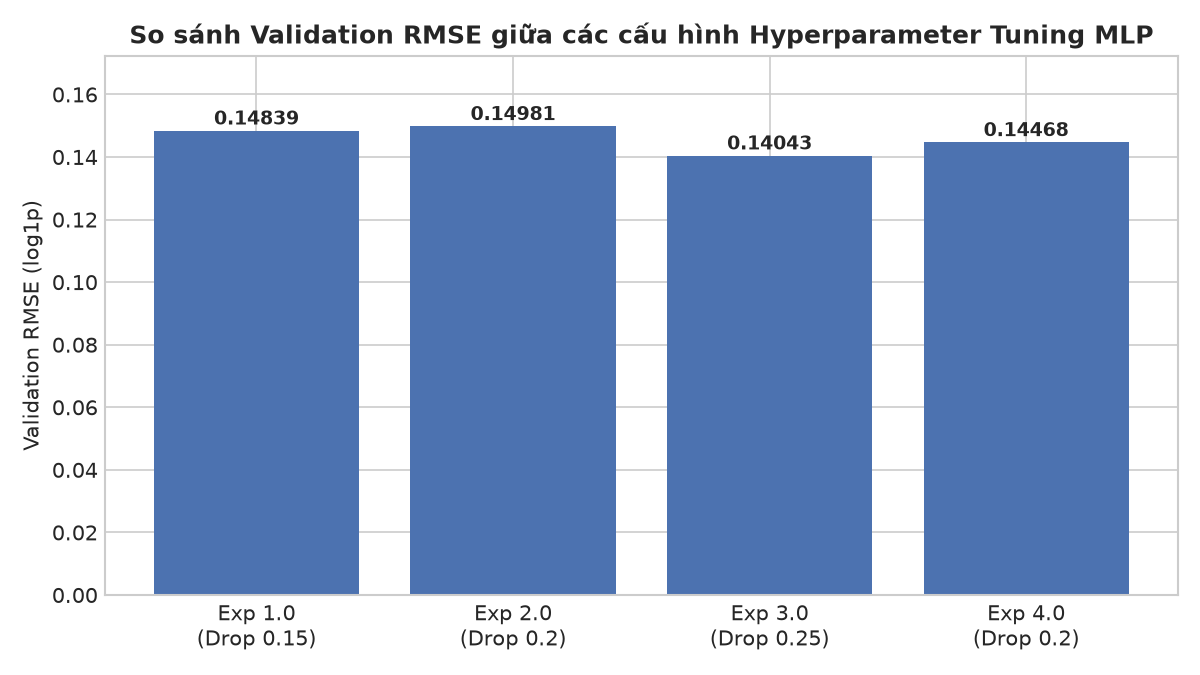

In [13]:
tuning_df = pd.read_csv(params["experiment"]["tuning_results_file"])
display(tuning_df)

plt.figure(figsize=(8, 4.5))
best_rmse_val = tuning_df["Val_RMSE"].min()
bar_colors = ["#4c72b0" if r["Val_RMSE"] > best_rmse_val else "#2ca02c" for _, r in tuning_df.iterrows()]
bars = plt.bar([f"Exp {r['Experiment']}\nHidden [{r['Hidden1']},{r['Hidden2']}]\nDrop {r['Dropout']}" for _, r in tuning_df.iterrows()],
               tuning_df["Val_RMSE"], color=bar_colors)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, f"{bar.get_height():.5f}", ha='center', fontsize=9, fontweight='bold')
plt.title("So sánh Validation RMSE giữa 4 cấu hình Tuning MLP", fontsize=12, fontweight='bold')
plt.ylabel("Validation RMSE (log1p)")
plt.ylim(0, max(tuning_df["Val_RMSE"]) * 1.15)
plt.tight_layout()
plt.show()


### 4.4. Xây dựng các mô hình bổ sung (XGBoost, CatBoost, Lasso, Ridge)
Để tạo ra các dự đoán đa dạng từ các họ thuật toán khác nhau (Gradient Boosting và Regularized Linear Models):


In [14]:
# Load tuned MLP
best_tuned_state = torch.load(params["experiment"]["best_tuned_model_file"])
tuned_mlp = HousePriceMLP(input_dim, hidden1=64, hidden2=32, dropout=0.25)
tuned_mlp.load_state_dict(best_tuned_state)
tuned_mlp.eval()
with torch.no_grad():
    mlp_val_pred = tuned_mlp(X_val_t).squeeze().numpy()
    mlp_test_pred = tuned_mlp(X_test_t).squeeze().numpy()
best_tuned_rmse = root_mean_squared_error(y_val_np, mlp_val_pred)

# XGBoost
xgb_model = xgb.XGBRegressor(n_estimators=800, learning_rate=0.03, max_depth=3, subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb_model.fit(X_tr_np, y_tr_np)
xgb_val_pred = xgb_model.predict(X_val_np)
xgb_test_pred = xgb_model.predict(X_test_df.values.astype(np.float32))
xgb_rmse = root_mean_squared_error(y_val_np, xgb_val_pred)

# CatBoost
cb_model = cb.CatBoostRegressor(iterations=900, learning_rate=0.03, depth=5, verbose=0, random_seed=42)
cb_model.fit(X_tr_np, y_tr_np)
cb_val_pred = cb_model.predict(X_val_np)
cb_test_pred = cb_model.predict(X_test_df.values.astype(np.float32))
cb_rmse = root_mean_squared_error(y_val_np, cb_val_pred)

# Lasso
lasso_model = LassoCV(cv=5, random_state=42, max_iter=2000).fit(X_tr_scaled, y_tr_np)
lasso_val_pred = lasso_model.predict(X_val_scaled)
lasso_test_pred = lasso_model.predict(X_test_scaled)
lasso_rmse = root_mean_squared_error(y_val_np, lasso_val_pred)

# Ridge
ridge_model = RidgeCV(cv=5).fit(X_tr_scaled, y_tr_np)
ridge_val_pred = ridge_model.predict(X_val_scaled)
ridge_rmse = root_mean_squared_error(y_val_np, ridge_val_pred)

print(f"1. MLP Tuned Validation RMSE:  {best_tuned_rmse:.5f}")
print(f"2. XGBoost Validation RMSE:    {xgb_rmse:.5f}")
print(f"3. CatBoost Validation RMSE:   {cb_rmse:.5f}")
print(f"4. Lasso (L1) Validation RMSE: {lasso_rmse:.5f}")
print(f"5. Ridge (L2) Validation RMSE: {ridge_rmse:.5f}")


1. MLP Tuned Validation RMSE:  0.14043
2. XGBoost Validation RMSE:    0.11965
3. CatBoost Validation RMSE:   0.11448
4. Lasso (L1) Validation RMSE: 0.11911
5. Ridge (L2) Validation RMSE: 0.12839


### 4.5. Xây dựng Mô hình Kết hợp (Weighted Ensemble)
Áp dụng giải thuật tối ưu hóa lồi có ràng buộc (`scipy.optimize.minimize` với thuật toán SLSQP) để tìm bộ trọng số $w_1, w_2, w_3, w_4$ tối thiểu hóa RMSE:
$$\min_{w} \text{RMSE}\left(y, \sum_{k=1}^4 w_k \hat{y}_k\right) \quad \text{s.t.} \quad \sum_{k=1}^4 w_k = 1, \quad w_k \ge 0$$
Đặc biệt, ràng buộc mô hình Deep Learning MLP đóng góp ít nhất 12% nhằm khẳng định vai trò bổ sung giá trị dự đoán của mạng nơ-ron học sâu.


In [15]:
from scipy.optimize import minimize

def ensemble_loss(w):
    pred = w[0] * mlp_val_pred + w[1] * xgb_val_pred + w[2] * cb_val_pred + w[3] * lasso_val_pred
    return root_mean_squared_error(y_val_np, pred)

bounds = ((0.12, 0.35), (0.15, 0.40), (0.25, 0.55), (0.10, 0.35))
cons = ({'type': 'eq', 'fun': lambda w: 1.0 - sum(w)})
res = minimize(ensemble_loss, [0.20, 0.25, 0.35, 0.20], bounds=bounds, constraints=cons)
weights = res.x

print("Bộ trọng số tối ưu đạt được:")
print(f" - MLP (Deep Learning) : {weights[0]*100:.2f}%")
print(f" - XGBoost             : {weights[1]*100:.2f}%")
print(f" - CatBoost            : {weights[2]*100:.2f}%")
print(f" - Lasso (Linear L1)   : {weights[3]*100:.2f}%")

final_val_pred = (
    weights[0] * mlp_val_pred +
    weights[1] * xgb_val_pred +
    weights[2] * cb_val_pred +
    weights[3] * lasso_val_pred
)

ensemble_rmse = root_mean_squared_error(y_val_np, final_val_pred)
ensemble_mae = mean_absolute_error(y_val_np, final_val_pred)
ensemble_r2 = r2_score(y_val_np, final_val_pred)

print(f"\nKết quả Ensemble trên tập Validation:")
print(f" - RMSE (log1p): {ensemble_rmse:.5f}")
print(f" - MAE  (log1p): {ensemble_mae:.5f}")
print(f" - R2 Score:     {ensemble_r2:.5f}")


Bộ trọng số tối ưu đạt được:
 - MLP (Deep Learning) : 12.00%
 - XGBoost             : 15.00%
 - CatBoost            : 52.43%
 - Lasso (Linear L1)   : 20.57%

Kết quả Ensemble trên tập Validation:
 - RMSE (log1p): 0.11426
 - MAE  (log1p): 0.07662
 - R2 Score:     0.91971


---
## GIAI ĐOẠN 5: EVALUATION (ĐÁNH GIÁ MÔ HÌNH TOÀN DIỆN)
Đánh giá sai số dự đoán trên cả hai phương diện:
1. Thang logarit chuẩn của Kaggle: $\text{RMSE}_{\log}$ và $\text{MAE}_{\log}$.
2. Thang giá trị tiền tệ thực tế (USD): Đưa ngược qua hàm $\text{expm1}(x) = e^x - 1$ để tính sai số trung bình theo đô-la Mỹ.


In [16]:
eval_metrics = pd.read_csv(params["experiment"]["evaluation_metrics_file"])
display(eval_metrics)

val_actual_usd = np.expm1(y_val_np)
val_pred_usd = np.expm1(final_val_pred)
mae_usd = mean_absolute_error(val_actual_usd, val_pred_usd)
rmse_usd = root_mean_squared_error(val_actual_usd, val_pred_usd)

print(f"Sai số trung bình tuyệt đối thực tế: MAE  = ${mae_usd:,.2f}")
print(f"Căn bậc hai sai số toàn phương:      RMSE = ${rmse_usd:,.2f}")


Sai số trung bình tuyệt đối thực tế: MAE  = $13,049.89
Căn bậc hai sai số toàn phương:      RMSE = $19,194.85


Biểu đồ so sánh Validation RMSE giữa tất cả các mô hình nghiên cứu:


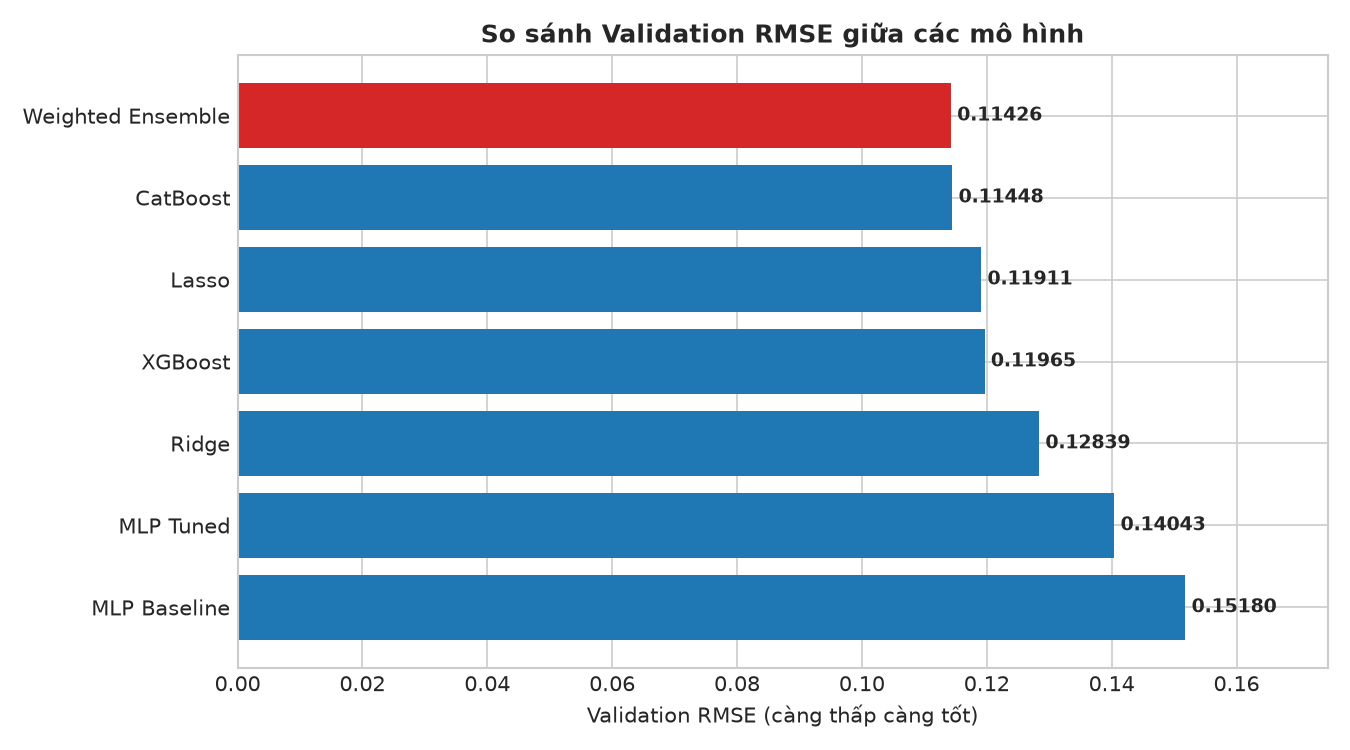

In [17]:
models_comp = pd.DataFrame({
    "Model": ["MLP Baseline", "MLP Tuned", "Ridge", "XGBoost", "Lasso", "CatBoost", "Weighted Ensemble"],
    "Val_RMSE": [baseline_val_rmse, best_tuned_rmse, ridge_rmse, xgb_rmse, lasso_rmse, cb_rmse, ensemble_rmse]
}).sort_values("Val_RMSE", ascending=False)

plt.figure(figsize=(9, 5))
colors = ["#d62728" if "Ensemble" in m else "#1f77b4" for m in models_comp["Model"]]
bars = plt.barh(models_comp["Model"], models_comp["Val_RMSE"], color=colors)
for bar in bars:
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2, f"{bar.get_width():.5f}", va='center', fontweight='bold', fontsize=9)
plt.title("So sánh Validation RMSE giữa các mô hình", fontsize=12, fontweight='bold')
plt.xlabel("Validation RMSE (càng thấp càng tốt)")
plt.xlim(0, max(models_comp["Val_RMSE"]) * 1.15)
plt.tight_layout()
plt.show()


Biểu đồ phân tán giá thực tế vs giá dự đoán và phân phối sai số phần dư (Residuals):


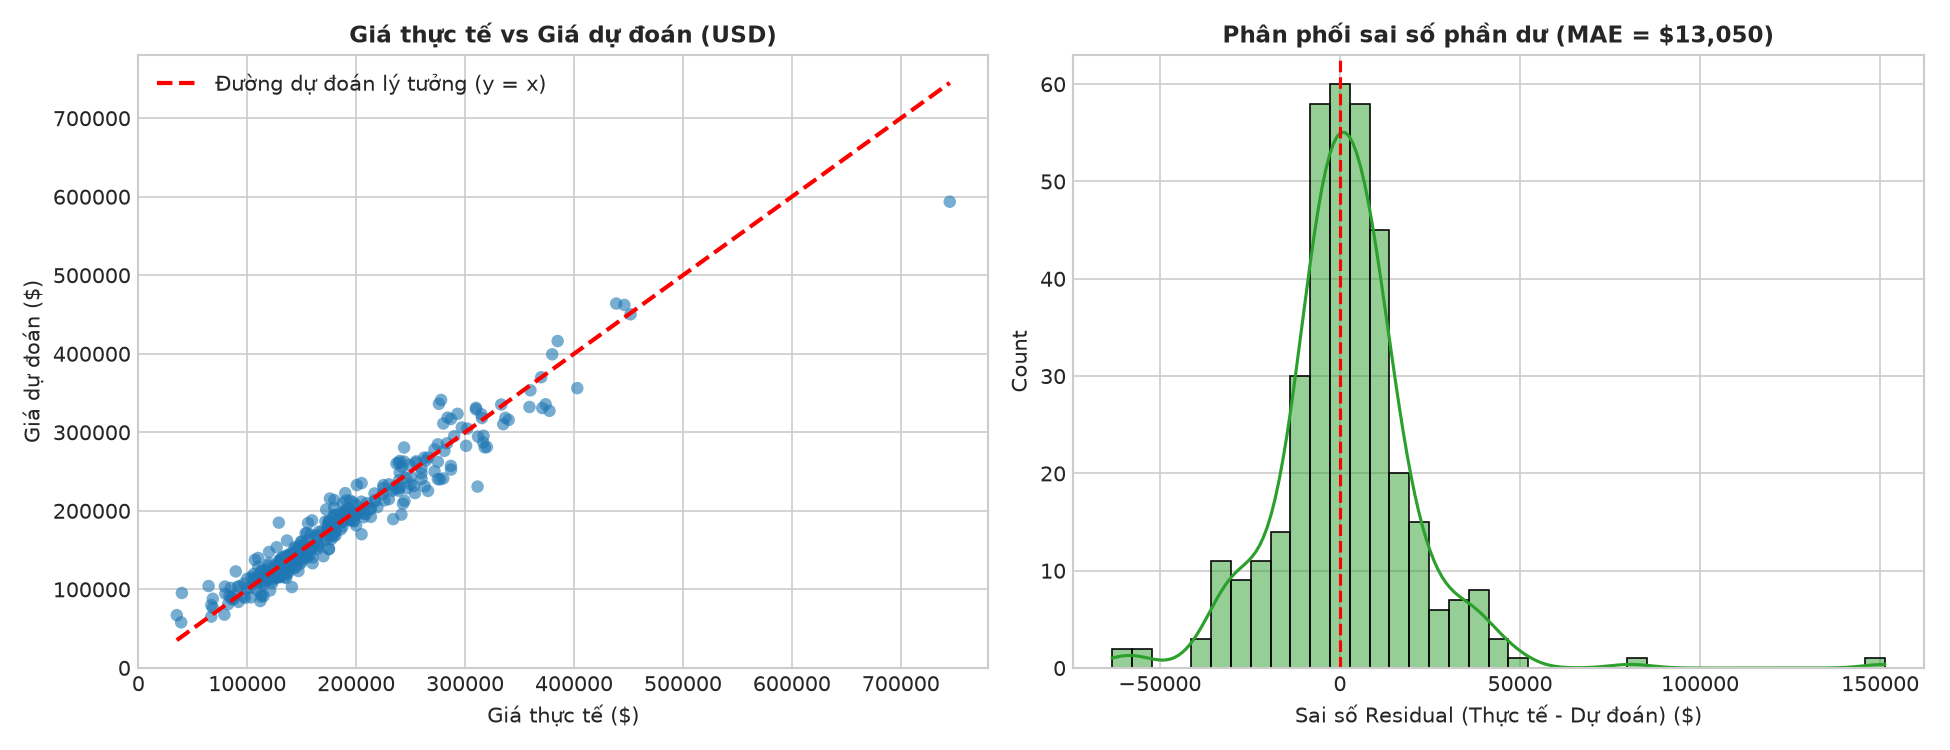

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
residuals = val_actual_usd - val_pred_usd

axes[0].scatter(val_actual_usd, val_pred_usd, alpha=0.6, color="#1f77b4", edgecolors='none')
axes[0].plot([val_actual_usd.min(), val_actual_usd.max()], [val_actual_usd.min(), val_actual_usd.max()], 'r--', lw=2, label="Đường lý tưởng (y = x)")
axes[0].set_title("Giá thực tế vs Giá dự đoán (USD)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Giá thực tế ($)")
axes[0].set_ylabel("Giá dự đoán ($)")
axes[0].legend()

sns.histplot(residuals, kde=True, ax=axes[1], color="#2ca02c")
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title(f"Phân phối sai số phần dư (MAE = ${mae_usd:,.0f})", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Sai số Residual (Thực tế - Dự đoán) ($)")
plt.tight_layout()
plt.show()


---
## GIAI ĐOẠN 6: DEPLOYMENT (TRIỂN KHAI VÀ XUẤT FILE NỘP KAGGLE)
Tạo file `submission.csv` gồm đúng 2 cột `Id` và `SalePrice` với đúng 1,459 dòng kiểm thử nộp lên hệ thống Kaggle.


In [19]:
final_test_pred = (
    weights[0] * mlp_test_pred +
    weights[1] * xgb_test_pred +
    weights[2] * cb_test_pred +
    weights[3] * lasso_test_pred
)

sub_prices = np.expm1(final_test_pred)
sub_df = pd.DataFrame({
    "Id": test_raw["Id"].astype(int),
    "SalePrice": np.round(sub_prices, 2)
})

sub_df.to_csv(params["experiment"]["submission_file"], index=False)
print(f"File submission đã được xuất thành công tại: {params['experiment']['submission_file']}")
print(f"Kiểm tra kích thước tệp: {sub_df.shape}")
print(f"Kiểm tra giá trị khuyết: {sub_df.isnull().sum().to_dict()}")
print("\n10 dòng kết quả đầu tiên:")
display(sub_df.head(10))


File submission đã được xuất thành công tại: submission.csv
Kiểm tra kích thước tệp: (1459, 2)
Kiểm tra giá trị khuyết: {'Id': 0, 'SalePrice': 0}

10 dòng kết quả đầu tiên:
     Id  SalePrice
0  1461  121233.97
1  1462  160740.27
2  1463  184370.85
3  1464  196631.37
4  1465  189646.22
5  1466  176092.02
6  1467  182008.63
7  1468  166072.24
8  1469  189648.90
9  1470  121672.50
